In [ ]:
import spacy

In [ ]:
!python -m spacy download es_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 41.8 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
nlp = spacy.load("es_core_news_sm")  #cargar corpus español

In [ ]:
nlp.max_length = 3000000

In [ ]:
#cargar el don quijote en formato texto
import requests

url= "https://babel.upm.es/~angel/teaching/pps/quijote.txt"
response = requests.get(url)
text = response.text

In [ ]:
len(text)

2097953

In [ ]:
#limpiar al text quitando espacios
text = text.replace("\n", " ").replace("\r", " ")

In [ ]:
#objeto tipo documento de spaCy
doc=nlp(text)
type(doc)

spacy.tokens.doc.Doc

Un **lemma** (plural: "lemmas" o "lemmata") es la forma base o raíz de una palabra, que se usa para representar todas sus variantes flexionadas. En lingüística y procesamiento de lenguaje natural, un lema permite agrupar las distintas formas de una palabra en un solo término, facilitando el análisis y la manipulación del lenguaje.

### Ejemplo de lematización
En inglés:
- Las palabras "running," "ran," y "runs" tienen como lema "run."
  
En español:
- Las palabras "comiendo," "comeré," y "comimos" tienen como lema "comer."

### Importancia de la Lematización en Procesamiento de Lenguaje Natural (PLN)
La lematización es clave en el PLN porque permite reducir las palabras a su forma canónica o raíz, haciendo que las distintas formas de una palabra se traten como una sola entidad. Esto es útil en tareas como:
- **Análisis de sentimientos**
- **Clasificación de texto**
- **Búsqueda de información**
  
La lematización, a diferencia de la **stemming** (radicación), no solo recorta palabras, sino que se basa en el contexto y las reglas lingüísticas, ofreciendo resultados más precisos.

In [ ]:
# 1. Limpieza del texto y extracción de palabras relevantes
import string
words = [
    token.lemma_.lower() for token in doc
    if not token.is_stop and not token.is_punct and token.lemma_ not in string.punctuation
]


In [ ]:
words

['ingenioso',
 'hidalgo',
 'don',
 'quijote',
 'mancha',
 '  ',
 'tasa',
 ' ',
 'juan',
 'gallo',
 'andrada',
 'escribano',
 'cámara',
 'rey',
 'señor',
 'residir',
 'consejo',
 'certifico',
 'dar',
 'fe',
 'haber',
 'ver',
 'señor',
 'del ',
 'libro',
 'intitulado',
 'ingenioso',
 'hidalgo',
 'mancha',
 'compuesto',
 'miguel',
 'cervantes',
 'saavedra',
 'tasar',
 'pliego',
 'libro',
 'maravedís',
 'ochenta',
 'pliego',
 'precio',
 'montar',
 'libro',
 'dociento',
 'noventa',
 'maravedís',
 'vender',
 'papel',
 'licencia',
 'precio',
 'vender',
 'mandar',
 'tasa',
 'poner',
 'principio',
 'libro',
 'vender',
 'dello',
 'conste',
 'dar',
 'presente',
 'valladolid',
 'veinte',
 'mes',
 'deciembre',
 'mil',
 'seisciento',
 'año',
 ' ',
 'juan',
 'gallo',
 'andrada',
 ' ',
 'testimonio',
 'erratas',
 ' ',
 'libro',
 'cosa',
 'digno',
 'corresponder',
 'original',
 'testimonio',
 'correcto',
 'dar',
 'fee',
 'colegio',
 'madre',
 'dios',
 'teólogos',
 'universidad',
 'alcalá',
 'diciembre'

In [ ]:
from collections import Counter
word_freqs = Counter(words)
most_common_words = word_freqs.most_common(200)  # Obtener las 200 palabras más comunes


most_common_words

[(' ', 4848),
 ('don', 2650),
 ('quijote', 1653),
 ('sancho', 1629),
 ('señor', 1108),
 ('ver', 1047),
 ('decir', 1015),
 ('   ', 1010),
 ('merced', 967),
 ('caballero', 936),
 ('querer', 924),
 ('venir', 811),
 ('cosa', 788),
 ('-dijo', 766),
 ('dar', 671),
 ('-respondió', 590),
 ('poder', 553),
 ('señora', 550),
 ('parecer', 532),
 ('hacer', 532),
 ('mano', 531),
 ('dejar', 525),
 ('quijote-', 522),
 ('poner', 520),
 ('haber', 514),
 ('sancho-', 507),
 ('volver', 504),
 ('dios', 498),
 ('salir', 439),
 ('pasar', 406),
 ('llegar', 403),
 ('tener', 400),
 ('mundo', 398),
 ('responder', 391),
 ('pensar', 390),
 ('quedar', 381),
 ('lugar', 372),
 ('tiempo', 366),
 ('casa', 362),
 ('vida', 361),
 ('tanto', 357),
 ('hombre', 356),
 ('hallar', 353),
 ('andante', 353),
 ('razón', 351),
 ('llamar', 349),
 ('ser', 339),
 ('padre', 327),
 ('tomar', 320),
 ('amigo', 316),
 ('pie', 316),
 ('voz', 309),
 ('escudero', 305),
 ('entender', 304),
 ('ojo', 303),
 ('panza', 303),
 ('ir', 299),
 ('llevar

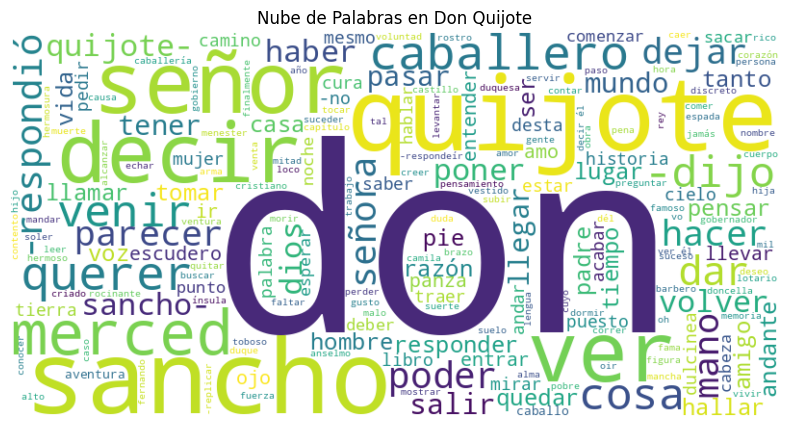

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

wordcloud = WordCloud(
    width=800, height=400, max_words=200, background_color="white",
).generate_from_frequencies(dict(most_common_words))

# Visualización de la nube de palabras
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Nube de Palabras en Don Quijote")
plt.show()

En procesamiento de lenguaje natural, un **n-grama** es una secuencia de \( n \) elementos (palabras, caracteres, o sílabas) en un texto, donde "n" indica el número de elementos en cada grupo. Se utiliza para analizar patrones de palabras o caracteres y para modelar relaciones en el texto.

### Tipos de N-gramas

1. **Unigrama** (\( n=1 \))  
   - Se considera cada palabra individualmente.
   - Ejemplo: Para el texto "ChatGPT es útil", los unigramas son: ["ChatGPT", "es", "útil"].

2. **Bigrama** (\( n=2 \))  
   - Agrupa las palabras en pares consecutivos.
   - Ejemplo: Para el mismo texto, los bigramas son: ["ChatGPT es", "es útil"].

3. **Trigrama** (\( n=3 \))  
   - Agrupa las palabras en secuencias de tres.
   - Ejemplo: Para el texto "ChatGPT es muy útil", los trigramas son: ["ChatGPT es muy", "es muy útil"].

4. **N-gramas mayores** (\( n>3 \))  
   - Se pueden formar secuencias con cualquier longitud deseada. Por ejemplo, con \( n=4 \), tendríamos "ChatGPT es muy útil".

### Uso de N-gramas en PLN

Los n-gramas ayudan a capturar el contexto de palabras y modelar la probabilidad de ocurrencia de secuencias de palabras. Esto es útil en aplicaciones como:
- **Predicción de texto**: Usar bigramas o trigramas para sugerir la siguiente palabra en función del contexto.
- **Análisis de sentimientos**: Identificar combinaciones de palabras que reflejen emociones específicas.
- **Traducción automática**: Modelar secuencias para mejorar la calidad de las traducciones.

Los n-gramas también pueden usarse para la generación de texto, análisis de frecuencia de frases y extracción de relaciones léxicas en textos.

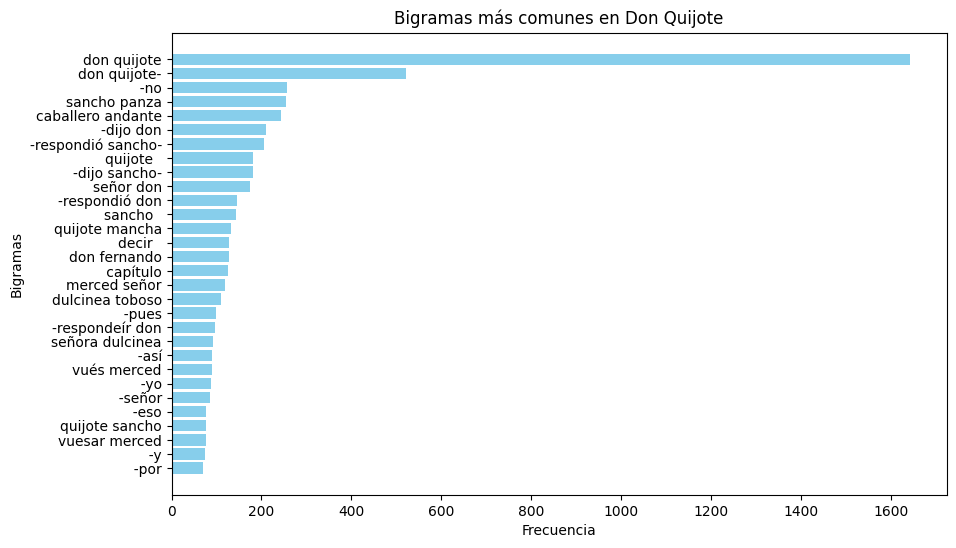

In [ ]:
import nltk
from nltk.util import ngrams
# Crear bigramas usando nltk
bigrams = list(ngrams(words, 2))
bigram_freqs = Counter(bigrams)
most_common_bigrams = bigram_freqs.most_common(30)  # Obtener los 30 bigramas más comunes

# 5. Visualización de Bigramas
# Crear un DataFrame para facilitar la visualización
import pandas as pd
bigram_df = pd.DataFrame(most_common_bigrams, columns=["Bigram", "Frequency"])
bigram_df["Bigram"] = bigram_df["Bigram"].apply(lambda x: " ".join(x))  # Convertir a texto

# Graficar los bigramas más comunes
plt.figure(figsize=(10, 6))
plt.barh(bigram_df["Bigram"], bigram_df["Frequency"], color="skyblue")
plt.xlabel("Frecuencia")
plt.ylabel("Bigramas")
plt.title("Bigramas más comunes en Don Quijote")
plt.gca().invert_yaxis()  # Invertir el eje y para que el bigrama más frecuente esté arriba
plt.show()

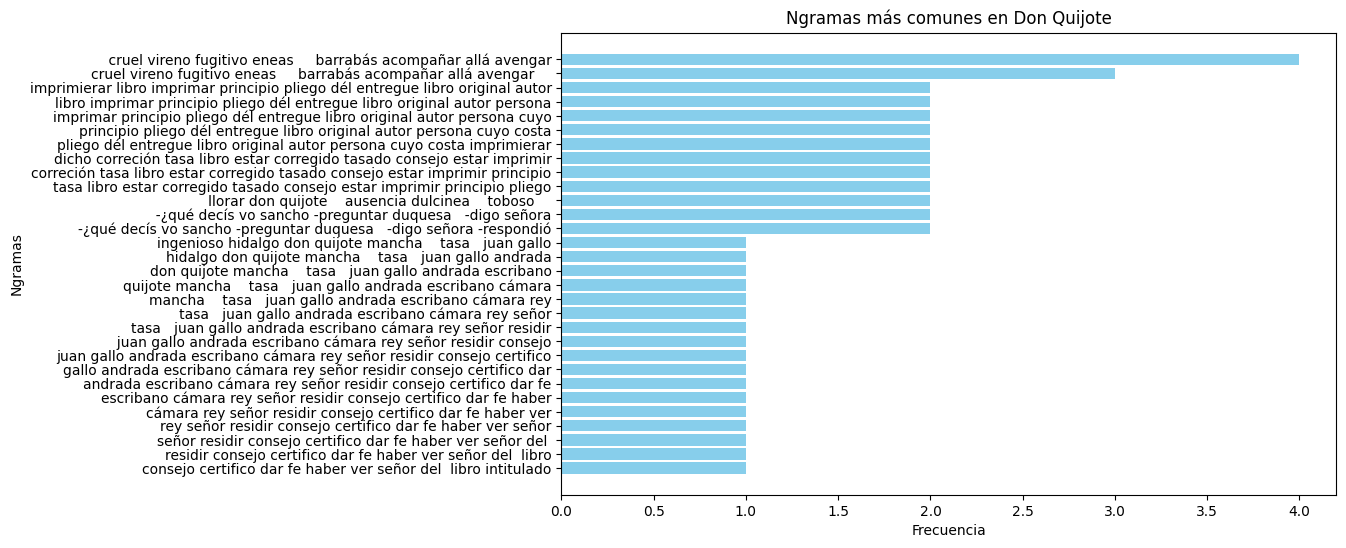

In [ ]:

# Crear bigramas usando nltk
bigrams = list(ngrams(words, 10))
bigram_freqs = Counter(bigrams)
most_common_bigrams = bigram_freqs.most_common(30)  # Obtener los 30 bigramas más comunes

# 5. Visualización de Bigramas
# Crear un DataFrame para facilitar la visualización
import pandas as pd
bigram_df = pd.DataFrame(most_common_bigrams, columns=["Bigram", "Frequency"])
bigram_df["Bigram"] = bigram_df["Bigram"].apply(lambda x: " ".join(x))  # Convertir a texto

# Graficar los bigramas más comunes
plt.figure(figsize=(10, 6))
plt.barh(bigram_df["Bigram"], bigram_df["Frequency"], color="skyblue")
plt.xlabel("Frecuencia")
plt.ylabel("Ngramas")
plt.title("Ngramas más comunes en Don Quijote")
plt.gca().invert_yaxis()  # Invertir el eje y para que el bigrama más frecuente esté arriba
plt.show()